In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Project paths
PROJECT_ROOT = Path.cwd()

# Support running the notebook from the project root
# or from a notebooks/ subdirectory.
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

print("Project directory:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

# Find ground-truth CSV
csv_files = list(DATA_DIR.glob("ISIC2018_Task3_Training_GroundTruth*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "Ground-truth CSV not found in the data directory."
    )

CSV_PATH = csv_files[0]
print("Ground-truth file:", CSV_PATH.name)

# Load dataset
df = pd.read_csv(CSV_PATH)

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Preview first five rows
display(df.head())


Project directory: /Users/sudhan/Desktop/PHD Document/CDU/cdu-phd-lifelong-quantum-ml
Data directory: /Users/sudhan/Desktop/PHD Document/CDU/cdu-phd-lifelong-quantum-ml/data
Ground-truth file: ISIC2018_Task3_Training_GroundTruth.csv

Dataset shape: (10015, 8)

Column names:
['image', 'MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']


,image,MEL,NV,BCC,AKIEC,BKL,DF,VASC
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:

# ============================================================
# STEP 2: DATA QUALITY EXPLORATION
# ============================================================

class_columns = [
    "MEL", "NV", "BCC", "AKIEC",
    "BKL", "DF", "VASC"
]

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

print(f"Total images: {len(df):,}")
print(f"Total lesion classes: {len(class_columns)}")
print(f"Total columns: {df.shape[1]}")

# 1. Missing values
print("\n1. MISSING VALUES")
missing_values = df.isnull().sum()
display(missing_values.to_frame(name="Missing Count"))

# 2. Duplicate image IDs
print("\n2. DUPLICATE IMAGE IDs")
duplicate_count = df["image"].duplicated().sum()
print(f"Duplicate image IDs: {duplicate_count}")

# 3. Check one-hot encoded labels
print("\n3. LABEL VALIDATION")

label_values = df[class_columns]

# Each row should have exactly one positive class
row_sums = label_values.sum(axis=1)

invalid_rows = (row_sums != 1).sum()

# All label values should be either 0 or 1
invalid_values = (~label_values.isin([0, 1])).sum().sum()

print(f"Invalid one-hot rows: {invalid_rows}")
print(f"Non-binary label values: {invalid_values}")

# 4. Data types
print("\n4. DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

# 5. Summary
print("\n5. DATA QUALITY SUMMARY")

quality_summary = pd.DataFrame({
    "Check": [
        "Missing values",
        "Duplicate image IDs",
        "Invalid one-hot rows",
        "Non-binary label values"
    ],
    "Count": [
        int(missing_values.sum()),
        int(duplicate_count),
        int(invalid_rows),
        int(invalid_values)
    ]
})

display(quality_summary)

if (quality_summary["Count"] == 0).all():
    print("\nAll CSV data quality checks passed.")
else:
    print("\nSome data quality issues require investigation.")


DATASET OVERVIEW
Total images: 10,015
Total lesion classes: 7
Total columns: 8

1. MISSING VALUES


,Missing Count
image,0
MEL,0
NV,0
BCC,0
AKIEC,0
BKL,0
DF,0
VASC,0



2. DUPLICATE IMAGE IDs
Duplicate image IDs: 0

3. LABEL VALIDATION
Invalid one-hot rows: 0
Non-binary label values: 0

4. DATA TYPES


,Data Type
image,object
MEL,float64
NV,float64
BCC,float64
AKIEC,float64
BKL,float64
DF,float64
VASC,float64



5. DATA QUALITY SUMMARY


,Check,Count
0,Missing values,0
1,Duplicate image IDs,0
2,Invalid one-hot rows,0
3,Non-binary label values,0



All CSV data quality checks passed.


,Class,Count,Percentage (%),Imbalance Ratio
0,NV,6705,66.95,58.30
1,MEL,1113,11.11,9.68
2,BKL,1099,10.97,9.56
3,BCC,514,5.13,4.47
4,AKIEC,327,3.27,2.84
5,VASC,142,1.42,1.23
6,DF,115,1.15,1.00



Majority class: NV
Minority class: DF
Overall imbalance ratio: 58.30:1


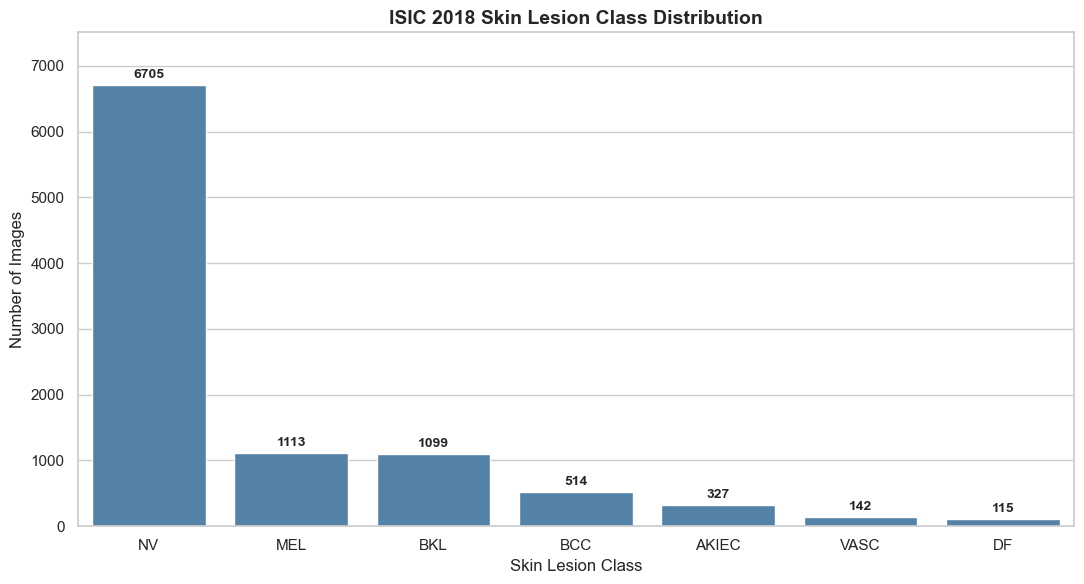

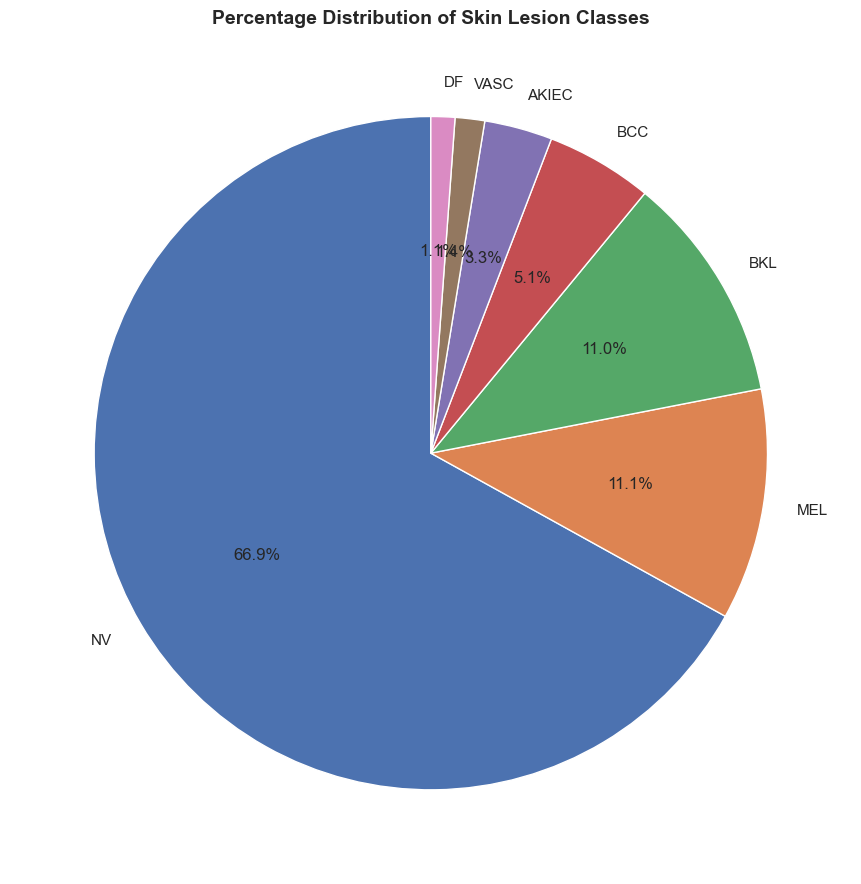

In [5]:

# ============================================================
# STEP 3: CLASS DISTRIBUTION AND IMBALANCE ANALYSIS
# ============================================================

# Convert one-hot labels to class names
df["class"] = df[class_columns].idxmax(axis=1)

# Calculate class frequencies
class_counts = df["class"].value_counts()

# Calculate percentages
class_percentages = (
    class_counts / len(df) * 100
)

# Calculate imbalance ratio relative to the smallest class
minority_count = class_counts.min()

class_distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage (%)": class_percentages.values,
    "Imbalance Ratio": (
        class_counts.values / minority_count
    )
})

display(class_distribution.round(2))

# Overall imbalance
majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

overall_ratio = (
    class_counts.max() / class_counts.min()
)

print(f"\nMajority class: {majority_class}")
print(f"Minority class: {minority_class}")
print(f"Overall imbalance ratio: {overall_ratio:.2f}:1")

# ------------------------------------------------------------
# Visualisation: Class distribution
# ------------------------------------------------------------


# ============================================================
# STEP 3: CLASS DISTRIBUTION VISUALISATION (FIXED)
# ============================================================

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=class_distribution,
    x="Class",
    y="Count",
    color="steelblue"
)

# Compatible with older Matplotlib versions
for i, count in enumerate(class_distribution["Count"]):
    ax.text(
        i,
        count + 60,
        str(count),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "ISIC 2018 Skin Lesion Class Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Skin Lesion Class")
plt.ylabel("Number of Images")

plt.ylim(0, class_distribution["Count"].max() * 1.12)

plt.tight_layout()
plt.show()

# ============================================================
# CLASS PERCENTAGE PIE CHART
# ============================================================

plt.figure(figsize=(9, 9))

plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Percentage Distribution of Skin Lesion Classes",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

TASK-WISE CLASS DISTRIBUTION


,Task,Class,Count,Task Total,Percentage (%)
0,Task 1,DF,115,442,26.02
1,Task 1,AKIEC,327,442,73.98
2,Task 2,BKL,1099,7804,14.08
3,Task 2,NV,6705,7804,85.92
4,Task 3,VASC,142,656,21.65
5,Task 3,BCC,514,656,78.35



TASK-WISE IMBALANCE RATIOS


,min,max,Imbalance Ratio
Task,,,
Task 1,115,327,2.84
Task 2,1099,6705,6.10
Task 3,142,514,3.62


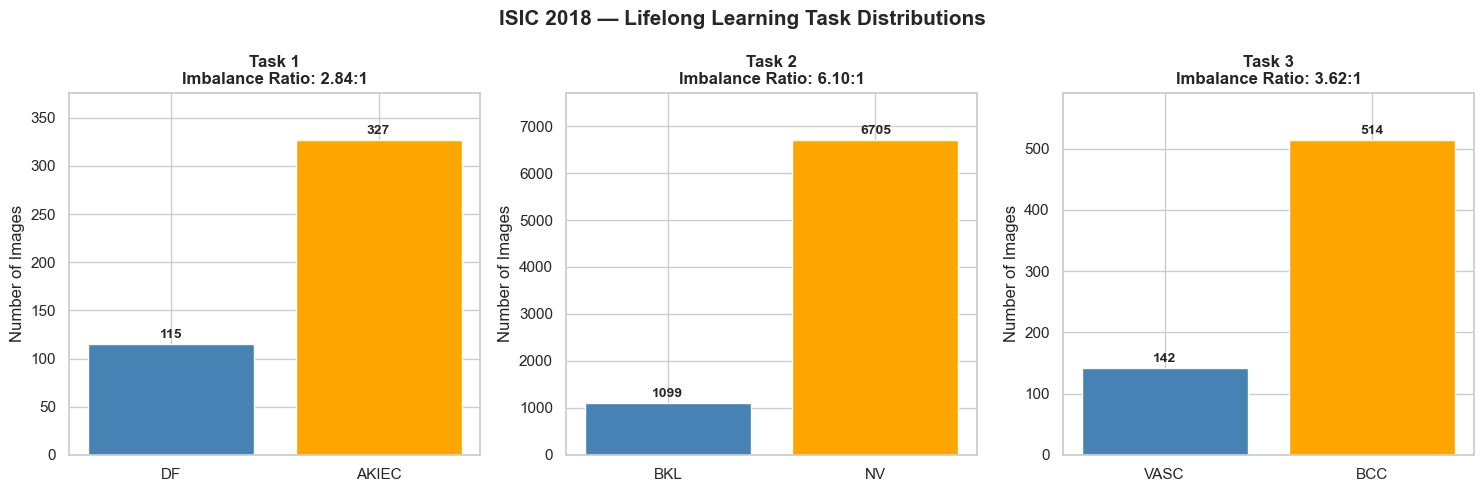

In [6]:

# ============================================================
# STEP 4: LIFELONG LEARNING TASK DISTRIBUTION
# ============================================================

# Task definitions used in the CDU experiment
task_classes = {
    "Task 1": ["DF", "AKIEC"],
    "Task 2": ["BKL", "NV"],
    "Task 3": ["VASC", "BCC"]
}

# Build task-wise distribution from original dataset
task_records = []

for task_name, classes in task_classes.items():
    for class_name in classes:
        count = int((df["class"] == class_name).sum())

        task_records.append({
            "Task": task_name,
            "Class": class_name,
            "Count": count
        })

task_df = pd.DataFrame(task_records)

# Calculate percentages within each task
task_df["Task Total"] = (
    task_df.groupby("Task")["Count"].transform("sum")
)

task_df["Percentage (%)"] = (
    task_df["Count"] / task_df["Task Total"] * 100
)

# Calculate imbalance ratio per task
task_imbalance = (
    task_df.groupby("Task")["Count"]
    .agg(["min", "max"])
)

task_imbalance["Imbalance Ratio"] = (
    task_imbalance["max"] / task_imbalance["min"]
)

print("TASK-WISE CLASS DISTRIBUTION")
display(task_df.round(2))

print("\nTASK-WISE IMBALANCE RATIOS")
display(task_imbalance.round(2))

# ------------------------------------------------------------
# Visualisation
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (task_name, classes) in zip(
    axes, task_classes.items()
):
    subset = task_df[task_df["Task"] == task_name]

    bars = ax.bar(
        subset["Class"],
        subset["Count"],
        color=["steelblue", "orange"]
    )

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + max(subset["Count"]) * 0.02,
            str(int(height)),
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

    ratio = task_imbalance.loc[
        task_name, "Imbalance Ratio"
    ]

    ax.set_title(
        f"{task_name}\nImbalance Ratio: {ratio:.2f}:1",
        fontweight="bold"
    )

    ax.set_ylabel("Number of Images")
    ax.set_ylim(0, max(subset["Count"]) * 1.15)

plt.suptitle(
    "ISIC 2018 — Lifelong Learning Task Distributions",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [7]:

# ============================================================
# STEP 5: EXPLORE PROCESSED TRAIN / TEST SPLITS
# ============================================================

from pathlib import Path

SEED = 4826
PROCESSED_DIR = DATA_DIR / "processed" / f"seed{SEED}"

print("Processed directory:", PROCESSED_DIR)

if not PROCESSED_DIR.exists():
    raise FileNotFoundError(
        f"Processed directory not found: {PROCESSED_DIR}"
    )

# Discover available processed files
processed_files = sorted(
    p for p in PROCESSED_DIR.rglob("*") if p.is_file()
)

print("\nAvailable processed files:")

for file in processed_files:
    print(
        file.relative_to(PROCESSED_DIR),
        f"({file.stat().st_size / 1024:.1f} KB)"
    )

# Preview CSV structure, if present
csv_paths = [
    p for p in processed_files
    if p.suffix.lower() == ".csv"
]

for path in csv_paths:
    print(f"\n--- {path.name} ---")

    preview = pd.read_csv(path, nrows=5)

    print("Columns:", preview.columns.tolist())
    display(preview)


Processed directory: /Users/sudhan/Desktop/PHD Document/CDU/cdu-phd-lifelong-quantum-ml/data/processed/seed4826

Available processed files:
metadata.json (0.5 KB)
test.csv (125.8 KB)
train.csv (503.0 KB)

--- test.csv ---
Columns: ['image', 'image_path', 'original_class', 'label', 'task']


,image,image_path,original_class,label,task
0,ISIC_0024319,data/ISIC2018_Task3_Training_Input/ISIC_002431...,NV,3,2
1,ISIC_0024328,data/ISIC2018_Task3_Training_Input/ISIC_002432...,NV,3,2
2,ISIC_0024331,data/ISIC2018_Task3_Training_Input/ISIC_002433...,BCC,5,3
3,ISIC_0024340,data/ISIC2018_Task3_Training_Input/ISIC_002434...,NV,3,2
4,ISIC_0024341,data/ISIC2018_Task3_Training_Input/ISIC_002434...,NV,3,2



--- train.csv ---
Columns: ['image', 'image_path', 'original_class', 'label', 'task']


,image,image_path,original_class,label,task
0,ISIC_0024306,data/ISIC2018_Task3_Training_Input/ISIC_002430...,NV,3,2
1,ISIC_0024307,data/ISIC2018_Task3_Training_Input/ISIC_002430...,NV,3,2
2,ISIC_0024308,data/ISIC2018_Task3_Training_Input/ISIC_002430...,NV,3,2
3,ISIC_0024309,data/ISIC2018_Task3_Training_Input/ISIC_002430...,NV,3,2
4,ISIC_0024311,data/ISIC2018_Task3_Training_Input/ISIC_002431...,NV,3,2


TRAIN / TEST SPLIT OVERVIEW
Training samples: 7,121
Testing samples:  1,781
Total samples:    8,902

Training percentage: 79.99%
Testing percentage:  20.01%

DATA LEAKAGE CHECK
Overlapping image IDs: 0
Training duplicates: 0
Testing duplicates: 0

CLASS DISTRIBUTION BY SPLIT


,Class,Train,Test,Total,Train (%),Test (%)
0,DF,92,23,115,80.00,20.00
1,AKIEC,262,65,327,80.12,19.88
2,BKL,879,220,1099,79.98,20.02
3,NV,5363,1342,6705,79.99,20.01
4,VASC,114,28,142,80.28,19.72
5,BCC,411,103,514,79.96,20.04



TASK AND LABEL VALIDATION
Invalid class/task mappings: 0


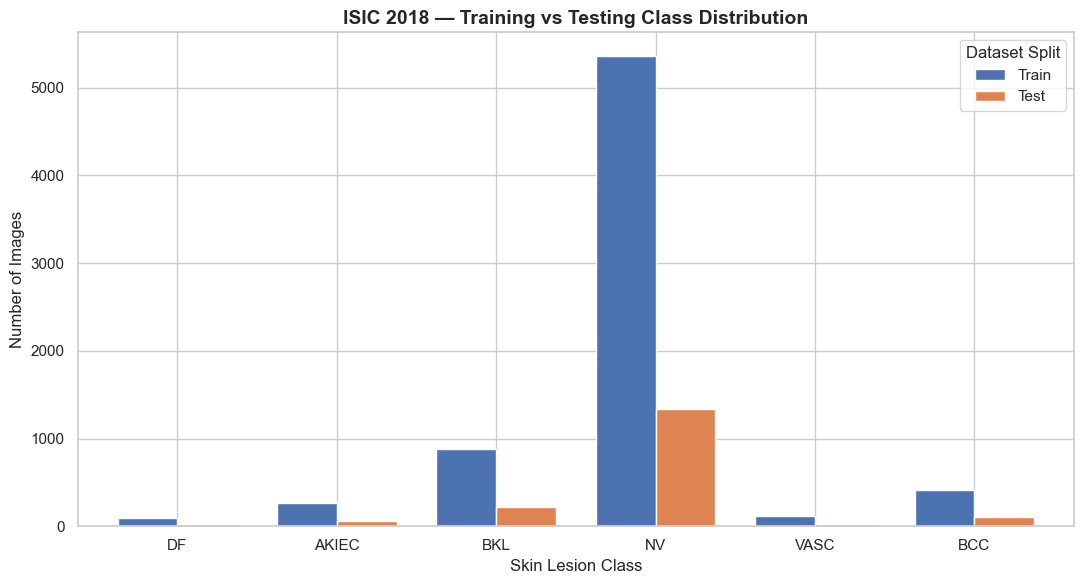

In [8]:

# ============================================================
# STEP 6: TRAIN / TEST SPLIT VALIDATION
# ============================================================

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("=" * 55)
print("TRAIN / TEST SPLIT OVERVIEW")
print("=" * 55)

total = len(train_df) + len(test_df)

print(f"Training samples: {len(train_df):,}")
print(f"Testing samples:  {len(test_df):,}")
print(f"Total samples:    {total:,}")

print(f"\nTraining percentage: {len(train_df)/total*100:.2f}%")
print(f"Testing percentage:  {len(test_df)/total*100:.2f}%")

# ------------------------------------------------------------
# 1. Check for duplicate images and data leakage
# ------------------------------------------------------------

train_ids = set(train_df["image"])
test_ids = set(test_df["image"])

overlap = train_ids.intersection(test_ids)

print("\nDATA LEAKAGE CHECK")
print(f"Overlapping image IDs: {len(overlap)}")
print(f"Training duplicates: {train_df['image'].duplicated().sum()}")
print(f"Testing duplicates: {test_df['image'].duplicated().sum()}")

# ------------------------------------------------------------
# 2. Class distribution
# ------------------------------------------------------------

class_order = ["DF", "AKIEC", "BKL", "NV", "VASC", "BCC"]

train_counts = (
    train_df["original_class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

test_counts = (
    test_df["original_class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

split_distribution = pd.DataFrame({
    "Class": class_order,
    "Train": train_counts.values,
    "Test": test_counts.values
})

split_distribution["Total"] = (
    split_distribution["Train"] + split_distribution["Test"]
)

split_distribution["Train (%)"] = (
    split_distribution["Train"]
    / split_distribution["Total"] * 100
)

split_distribution["Test (%)"] = (
    split_distribution["Test"]
    / split_distribution["Total"] * 100
)

print("\nCLASS DISTRIBUTION BY SPLIT")
display(split_distribution.round(2))

# ------------------------------------------------------------
# 3. Check task assignments and class labels
# ------------------------------------------------------------

expected_mapping = {
    "DF": (0, 1),
    "AKIEC": (1, 1),
    "BKL": (2, 2),
    "NV": (3, 2),
    "VASC": (4, 3),
    "BCC": (5, 3)
}

combined_df = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

invalid_mapping = combined_df.apply(
    lambda row: (
        row["label"], row["task"]
    ) != expected_mapping.get(row["original_class"]),
    axis=1
).sum()

print("\nTASK AND LABEL VALIDATION")
print(f"Invalid class/task mappings: {invalid_mapping}")

# ------------------------------------------------------------
# 4. Visualisation
# ------------------------------------------------------------

ax = split_distribution.set_index("Class")[
    ["Train", "Test"]
].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title(
    "ISIC 2018 — Training vs Testing Class Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Skin Lesion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")

plt.tight_layout()
plt.show()


TRAINING-ONLY CLASS WEIGHTS


,Class,Label,Train Count,Train (%),Class Weight
0,DF,0,92,1.2920,12.9004
1,AKIEC,1,262,3.6793,4.5299
2,BKL,2,879,12.3438,1.3502
3,NV,3,5363,75.3125,0.2213
4,VASC,4,114,1.6009,10.4108
5,BCC,5,411,5.7717,2.8877



Global training imbalance: 58.29:1

TASK-SPECIFIC TRAINING IMBALANCE


,Task,Samples,Minority Class,Majority Class,Imbalance Ratio
0,Task 1,354,DF,AKIEC,2.85
1,Task 2,6242,BKL,NV,6.10
2,Task 3,525,VASC,BCC,3.61


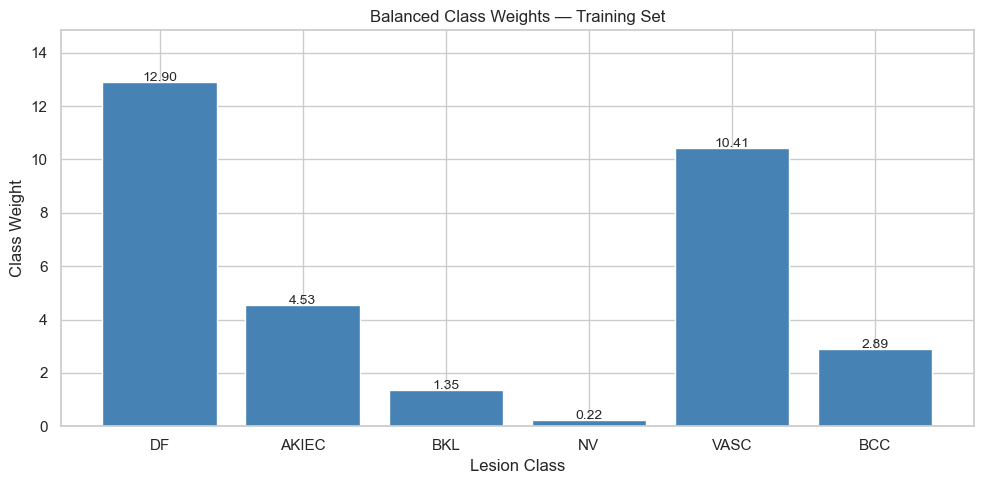

In [9]:

# ============================================================
# STEP 7: TRAINING-ONLY CLASS WEIGHTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use training data only — never the test set
class_order = ["DF", "AKIEC", "BKL", "NV", "VASC", "BCC"]

train_counts = (
    train_df["original_class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

n_samples = len(train_df)
n_classes = len(class_order)

# Balanced weights: N / (K * class_count)
class_weights = (
    n_samples / (n_classes * train_counts)
)

weights_df = pd.DataFrame({
    "Class": class_order,
    "Label": range(n_classes),
    "Train Count": train_counts.values,
    "Train (%)": train_counts.values / n_samples * 100,
    "Class Weight": class_weights.values
})

print("TRAINING-ONLY CLASS WEIGHTS")
display(weights_df.round(4))

# Global imbalance ratio
global_ratio = train_counts.max() / train_counts.min()

print(f"\nGlobal training imbalance: {global_ratio:.2f}:1")

# Task-specific training imbalance
task_summary = []

for task_id in sorted(train_df["task"].unique()):
    subset = train_df[train_df["task"] == task_id]

    counts = subset["original_class"].value_counts()

    task_summary.append({
        "Task": f"Task {task_id}",
        "Samples": len(subset),
        "Minority Class": counts.idxmin(),
        "Majority Class": counts.idxmax(),
        "Imbalance Ratio": counts.max() / counts.min()
    })

task_summary_df = pd.DataFrame(task_summary)

print("\nTASK-SPECIFIC TRAINING IMBALANCE")
display(task_summary_df.round(2))

# Plot class weights
plt.figure(figsize=(10, 5))

bars = plt.bar(
    weights_df["Class"],
    weights_df["Class Weight"],
    color="steelblue"
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        f"{height:.2f}",
        ha="center",
        fontsize=10
    )

plt.title("Balanced Class Weights — Training Set")
plt.xlabel("Lesion Class")
plt.ylabel("Class Weight")
plt.ylim(0, weights_df["Class Weight"].max() * 1.15)

plt.tight_layout()
plt.show()


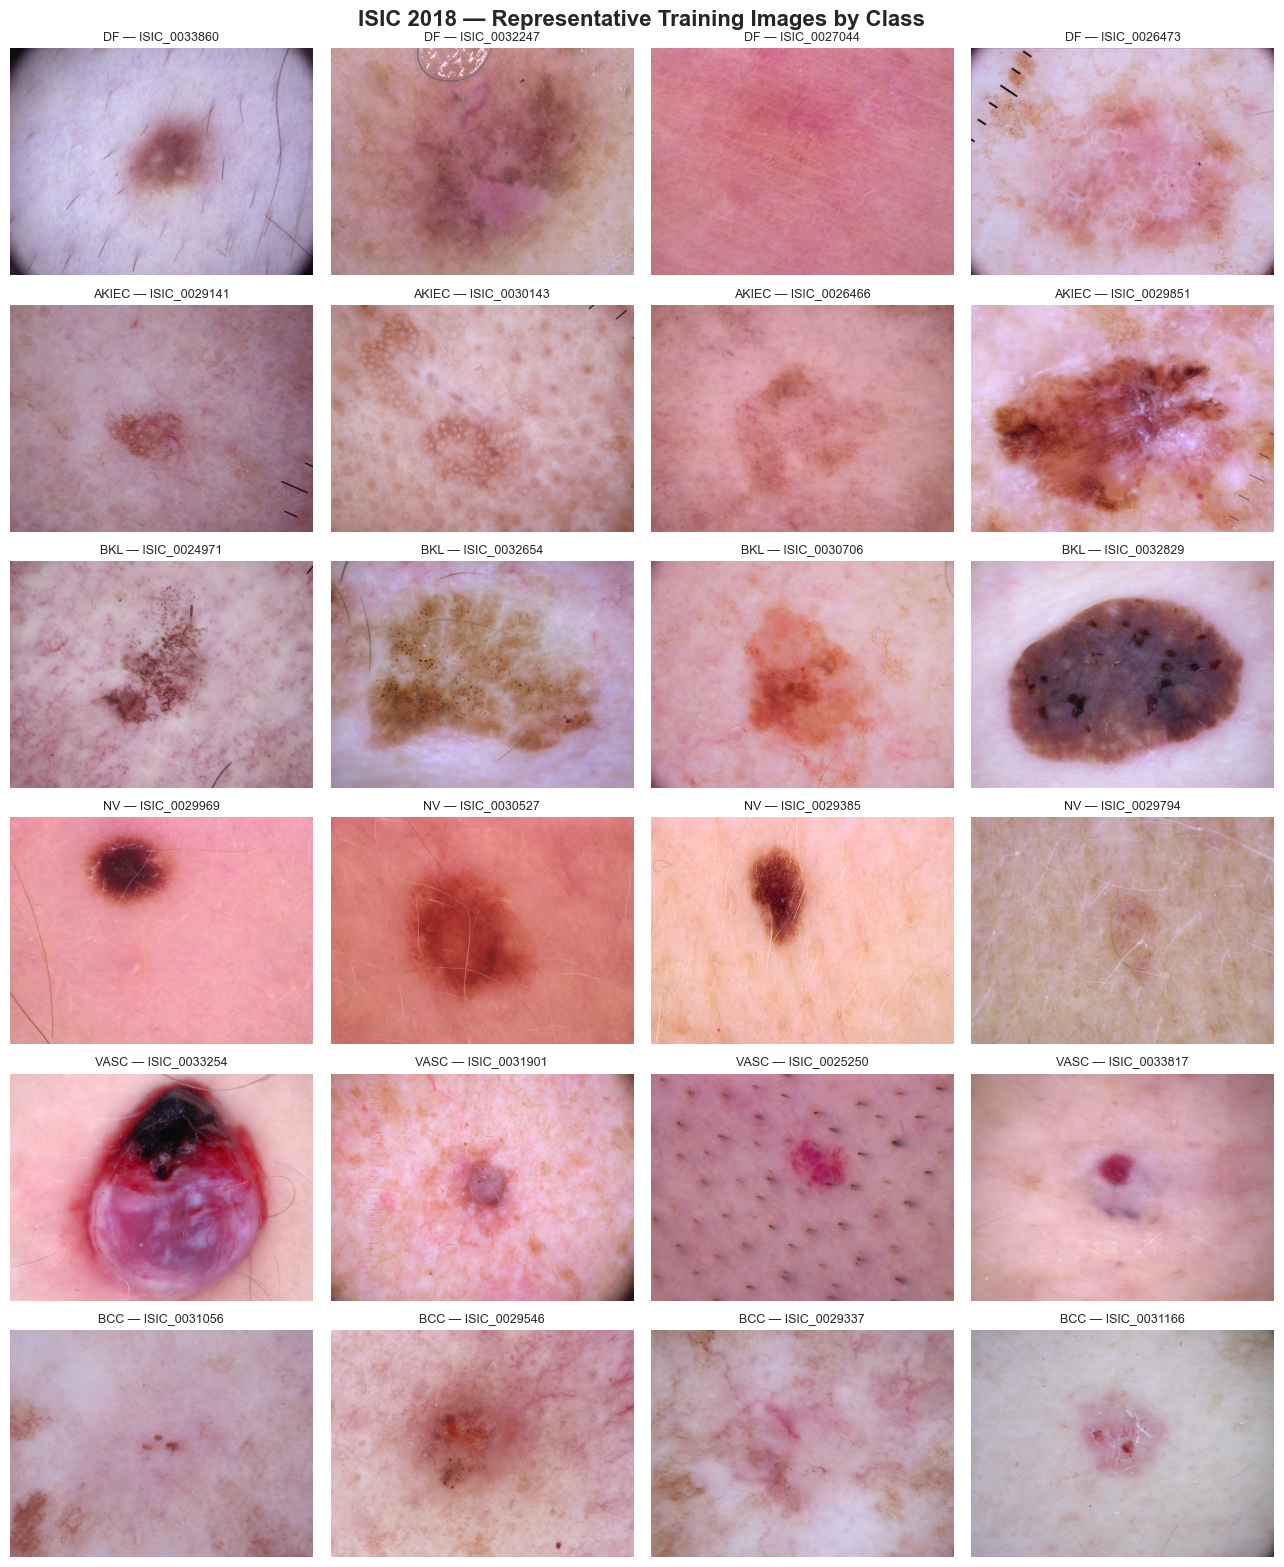

Figure saved to: /Users/sudhan/Desktop/PHD Document/CDU/cdu-phd-lifelong-quantum-ml/reports/class_samples.png


In [10]:

# ============================================================
# STEP 8: VISUALISE SKIN LESION IMAGES BY CLASS
# ============================================================

from PIL import Image

class_order = ["DF", "AKIEC", "BKL", "NV", "VASC", "BCC"]

samples_per_class = 4

fig, axes = plt.subplots(
    len(class_order),
    samples_per_class,
    figsize=(13, 16)
)

for row, class_name in enumerate(class_order):

    # Sample only from training data
    class_samples = train_df[
        train_df["original_class"] == class_name
    ].sample(
        n=samples_per_class,
        random_state=4826
    )

    for col, (_, sample) in enumerate(
        class_samples.iterrows()
    ):

        image_path = Path(sample["image_path"])

        if not image_path.is_absolute():
            image_path = PROJECT_ROOT / image_path

        ax = axes[row, col]

        if image_path.exists():
            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(
                0.5, 0.5,
                "Image not found",
                ha="center",
                va="center"
            )

        ax.set_title(
            f"{class_name} — {sample['image']}",
            fontsize=9
        )

        ax.axis("off")

plt.suptitle(
    "ISIC 2018 — Representative Training Images by Class",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save figure for PhD assessment report
output_path = PROJECT_ROOT / "reports" / "class_samples.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {output_path}")


IMAGE FILE INTEGRITY


,Count
status,
valid,500



IMAGE DIMENSION STATISTICS


,width,height,aspect_ratio,file_size_kb
count,500.0,500.0,500.00,500.00
mean,600.0,450.0,1.33,273.18
std,0.0,0.0,0.00,47.91
min,600.0,450.0,1.33,96.03
25%,600.0,450.0,1.33,252.10
50%,600.0,450.0,1.33,271.34
75%,600.0,450.0,1.33,299.88
max,600.0,450.0,1.33,423.65



IMAGE FORMAT DISTRIBUTION


,Count
format,
JPEG,500


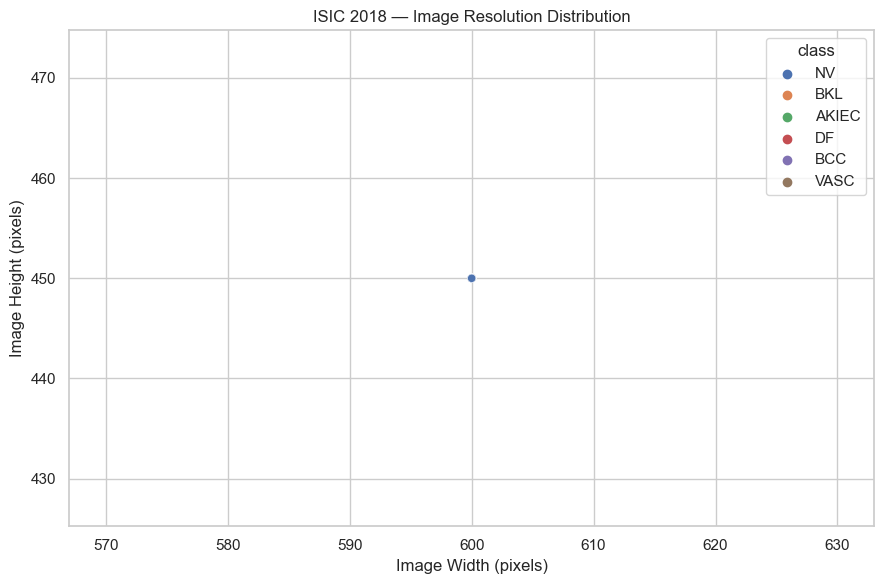

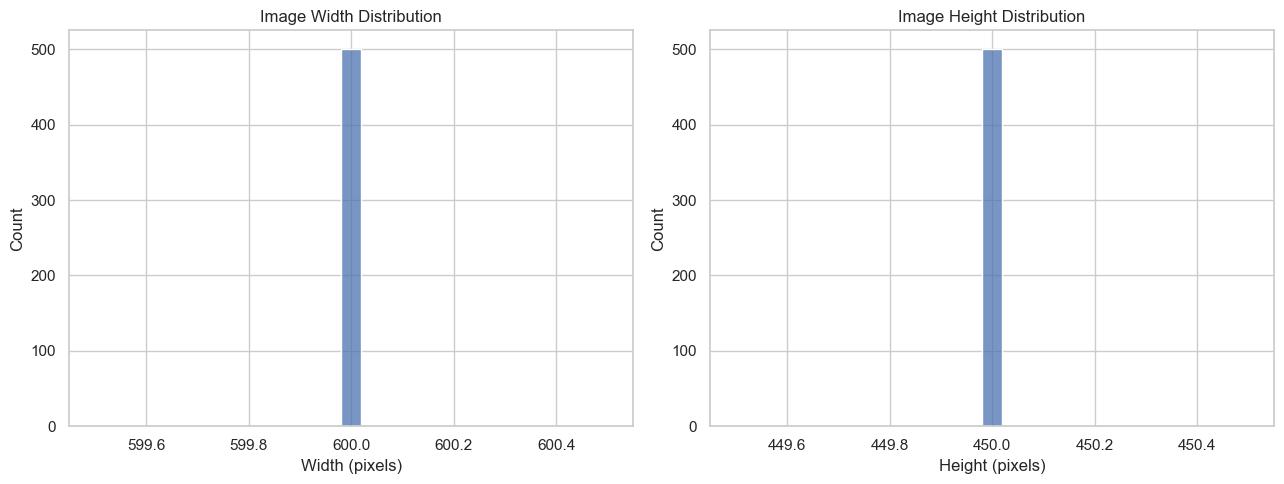

In [11]:

# ============================================================
# STEP 9: IMAGE DIMENSIONS AND FILE INTEGRITY
# ============================================================

from PIL import Image, UnidentifiedImageError
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the training split only
# Sample 500 images for efficient exploratory analysis
sample_size = min(500, len(train_df))

image_samples = train_df.sample(
    n=sample_size,
    random_state=4826
)

image_info = []

for _, row in image_samples.iterrows():

    image_path = Path(row["image_path"])

    if not image_path.is_absolute():
        image_path = PROJECT_ROOT / image_path

    if not image_path.exists():
        image_info.append({
            "image": row["image"],
            "class": row["original_class"],
            "status": "missing"
        })
        continue

    try:
        with Image.open(image_path) as img:
            width, height = img.size
            image_format = img.format

            # Decode image to detect unreadable files
            img.load()

        image_info.append({
            "image": row["image"],
            "class": row["original_class"],
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "file_size_kb": image_path.stat().st_size / 1024,
            "format": image_format,
            "status": "valid"
        })

    except (OSError, ValueError, UnidentifiedImageError):
        image_info.append({
            "image": row["image"],
            "class": row["original_class"],
            "status": "unreadable"
        })

image_info_df = pd.DataFrame(image_info)

# ------------------------------------------------------------
# 1. File integrity summary
# ------------------------------------------------------------

print("IMAGE FILE INTEGRITY")
display(
    image_info_df["status"]
    .value_counts()
    .to_frame(name="Count")
)

valid_images = image_info_df[
    image_info_df["status"] == "valid"
].copy()

print("\nIMAGE DIMENSION STATISTICS")

display(
    valid_images[
        ["width", "height", "aspect_ratio", "file_size_kb"]
    ].describe().round(2)
)

print("\nIMAGE FORMAT DISTRIBUTION")
display(
    valid_images["format"]
    .value_counts()
    .to_frame(name="Count")
)

# ------------------------------------------------------------
# 2. Image width vs height
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=valid_images,
    x="width",
    y="height",
    hue="class",
    alpha=0.7
)

plt.title("ISIC 2018 — Image Resolution Distribution")
plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Image width and height distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    valid_images["width"],
    bins=25,
    ax=axes[0]
)

axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    valid_images["height"],
    bins=25,
    ax=axes[1]
)

axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()
